[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ichristov/intermediate-fluid-mechanics/blob/main/extras/Hiemenz_flow.ipynb)


# LEARNING OBJECTIVE

After exploring this notebook, you will be able to derive Hiemenz's exact solution of the _full_ 2D iNS for viscous flow toward a plane stagnation point, which blends the ideal flow into a no-slip wall _without_ the boundary-layer approximation. You will also solve the resulting nonlinear boundary-value problem numerically and compare the solution with the ideal stagnation point flow.

# PRELIMINARIES

[run the next cell to set up Python environment customizations and load packages]

In [561]:
# interactive plots setup
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

# sympy setup
import sympy as sp
sp.init_printing()
from sympy.vector import *
from IPython.display import display, Math

# plotting customizations
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
size=16
params = {'legend.fontsize': 'large',
#          'figure.figsize': (20,8),
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25,
          'pdf.fonttype': 42 # pdf accessibility issue
        }
plt.rcParams.update(params)
%matplotlib inline

# numerics
import numpy as np
from scipy.integrate import solve_bvp
from scipy.optimize import root_scalar as nsolve

# for Colab only: to save plots as files and download them
#from google.colab import files

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

# HIEMENZ FLOW

The _full_ steady iNS, with no body force, are
\begin{alignat*}{3}
    \text{[COM]}\qquad &&\nabla\cdot\underline{v} &= 0,\\
    \text{[COLM]}\qquad &&\rho(\underline{v}\cdot\nabla)\underline{v} &= -\nabla p + \mu\nabla^2\underline{v}.
\end{alignat*}

From COLM, we know that $\underline{R} = \rho(\underline{v}\cdot\nabla)\underline{v} - \mu\nabla^2\underline{v}$ must equal $-\nabla p$.

In [562]:
# create a Cartesian coordinate system with SymPy
c = CoordSys3D('c')
a, nu, rho = sp.symbols('a nu rho', positive=True)
mu = rho*nu

In [563]:
# R = rho (v dot grad) v - mu grad^2 v, which must equal -grad p
def compute_R(v):
    omega = curl(v)
    v_del_v = sp.Rational(1, 2)*gradient(v & v) - (v ^ omega)
    laplacian_v = -curl(omega)
    return rho*v_del_v - mu*laplacian_v

But it gets better, since, if we take a curl, $\nabla\times\nabla p = \underline{0}$ and thus $\nabla\times\underline{R} = \underline{0}$. So, that becomes our governing equation, together with COM!

Furthermore, we'll use our favorite vector calculus identities, $(\underline{v}\cdot\nabla)\underline{v} = \tfrac{1}{2}\nabla(\underline{v}\cdot\underline{v}) - \underline{v}\times\underline{\omega}$ and, for an incompressible flow, $\nabla^2\underline{v} = -\nabla\times\underline{\omega}$.

Finally, we restrict ourselves to 2D flows:
$$
    \underline{v} = v_x(x,y) \,\underline{e}_x + v_y(x,y) \,\underline{e}_y.
$$

## Outer flow: ideal stagnation point flow

Near the stagnation point on a blunt body, the body looks flat. There, the ideal flow, from $F(z) = \tfrac{a}{2}z^2$ in [ideal flows in 2D](../ideal_flows_2D.ipynb), is
$$
    v_x^{\mathrm{ideal}}(x,y) = ax, \qquad v_y^{\mathrm{ideal}}(x,y) = -ay,
$$
where the constant $a>0$ is the _strain rate_, with units of s<sup>&minus;1</sup>. Let us check this flow field against the full iNS.

In [564]:
# the ideal stagnation point flow
v_ideal = a*c.x*c.i - a*c.y*c.j

# divergence of v
display(Math(r'\nabla\cdot\underline{v}^{\mathrm{ideal}} = ' + sp.latex(divergence(v_ideal))))

<IPython.core.display.Math object>

In [565]:
R_ideal = compute_R(v_ideal)
display(Math(r'\underline{R}^{\mathrm{ideal}} = ' + sp.latex(R_ideal)))

<IPython.core.display.Math object>

In [566]:
# curl R, which must vanish
display(Math(r'\nabla\times\underline{R}^{\mathrm{ideal}} = ' + sp.latex(curl(R_ideal))))

<IPython.core.display.Math object>

Apparently the full 2D steady iNS are satisfied. (The viscous forces, $\mu\nabla^2\underline{v}$, vanish because $\underline{v}$ is linear in $x$ and $y$.) 

But this ideal flow does not satisfy no slip: $v_x^{\mathrm{ideal}}(x,0) = ax \ne 0$. (It does satisfies no penetration: $v_y^{\mathrm{ideal}}(x,0) = -a\,0 = 0$.)

## Blended solution taking into account viscosity

As in Blasius' problem, we call the ideal flow along the wall the _external_ flow, $v_{x,e}(x) = v_x^{\mathrm{ideal}}(x,0) = ax$. For uniform flow past a flat plate ($v_{x,e} = V_0$), blending the ideal flow into no slip at the wall required the BL approximation (Blasius' problem in the [boundary layers](../boundary_layers.ipynb) notebook). 

Surprisingly, here, we won't need it. [Hiemenz (1911)](https://archive.org/details/dinglers-polytechnisches-journal-vol-326/page/321/mode/2up), a student of Prandtl, found an unusual similarity-like solution of the _full_ iNS that blends the ideal stagnation point flow into a no-slip wall at $y=0$:
$$
    v_x(x,y) = v_{x,e}(x)\, f'(\eta), \qquad v_y(x,y) = -\sqrt{a\nu}\, f(\eta), \qquad \eta = \frac{y}{\sqrt{\nu/a}}.
$$

There is no time in this problem, and the domain is semi-infinite ($-\infty < x < \infty$ and $y>0$), so the only length scale implied in this problem statement is $\sqrt{\nu/a}$. Therefore, $\eta$ is a dimensionless distance from the wall, but doesn't combine $x$ and $y$. Nevertheless, the problem eventually reduces to an ODE in terms of _only_ $f(\eta)$.

We follow Section 11.9 of _Incompressible Flow_ [(Panton, 2013)](https://doi.org/10.1002/9781118713075), which writes $F$ for our $f$.

Let's check if such a reduction works using SymPy.

In [567]:
# the Hiemenz form of the velocity
f = sp.Function('f')
eta_expr = c.y/sp.sqrt(nu/a)

# f'(eta) = (df/dy)/(d eta/dy), by the chain rule
fp = f(eta_expr).diff(c.y)/eta_expr.diff(c.y)

v = a*c.x*fp*c.i - sp.sqrt(a*nu)*f(eta_expr)*c.j

In [568]:
# to display results in terms of f(eta), substitute y = eta*sqrt(nu/a)
eta_s = sp.Symbol('eta')

def in_eta(expr):
    return sp.simplify(expr.subs(c.y, eta_s*sp.sqrt(nu/a)))

COM is satisfied for _any_ $f$:

In [569]:
# divergence of v
display(Math(r'\nabla\cdot\underline{v} = ' + sp.latex(in_eta(divergence(v)))))

<IPython.core.display.Math object>

As for the ideal flow, we compute $\underline{R}$ and its curl. Let's evaluate them in terms of $f$ and $\eta$.

In [570]:
R = compute_R(v)

# see what R actually looks like
display(Math(r'\underline{R} = ' + sp.latex(in_eta(R))))

<IPython.core.display.Math object>

In [571]:
# curl R, which must vanish
curl_R = in_eta(curl(R))
display(Math(r'\nabla\times\underline{R} = ' + sp.latex(curl_R)))

<IPython.core.display.Math object>

Integrating $ff'''$ by parts suggests that the terms in the inner parentheses are $\frac{d}{d\eta}\big[f''' + ff'' - (f')^2\big]$. SymPy cannot integrate $ff'''$ on its own, but we can check this guess: dividing by it should leave no $f$.

In [572]:
f_eta = f(eta_s)
bracket = f_eta.diff(eta_s, 3) + f_eta*f_eta.diff(eta_s, 2) - f_eta.diff(eta_s)**2

# z-component of curl R, divided by d(bracket)/d(eta)
ratio = sp.simplify((curl_R & c.k) / bracket.diff(eta_s))
label = r"\frac{(\nabla\times\underline{R})_z}{\frac{d}{d\eta}\big[f''' + ff'' - (f')^2\big]} = "
display(Math(label + sp.latex(ratio)))

<IPython.core.display.Math object>

So, the full 2D steady iNS reduce to:
$$
    \frac{d}{d\eta}\big[f''' + ff'' - (f')^2\big] = 0.
$$
Integrating once, the bracket is a constant. Far from the wall ($\eta\to\infty$), the flow must match the external flow, $v_x\to v_{x,e}(x)$, that is, $f'\to1$ and $f'',f'''\to0$, so the constant is $-1$. 

This gives the _Hiemenz ODE_ (Panton, Eq. (11.9.15)):
$$
    f''' + ff'' + 1 - (f')^2 = 0
$$
together with no penetration and no slip at the wall, and the matching BC:
\begin{alignat*}{4}
    v_y|_{y=0} &= 0& &\quad\Rightarrow\quad& f(0) &= 0,&\\
    v_x|_{y=0} &= 0& &\quad\Rightarrow\quad& f'(0) &= 0,&\\
    v_x|_{y\to\infty} &\to v_{x,e}& &\quad\Rightarrow\quad& f'(\infty) &= 1.&
\end{alignat*}

Notice that the ideal flow is simply $f = \eta$ and satisfies the ODE (and indeed the full 2D steady iNS) with $f(0) = 0$ and $f'(\infty)=1$, _but_ it does _not_ satisfy $f'(0)=0$ (it slips).

Interestingly, since the ODE has no parameters, a single solution characterizes the viscous flow at _any_ stagnation point, whatever the body, the flow speed and the fluid.

## Numerical solution

We set up the BVP as for Blasius' problem in the [boundary layers](../boundary_layers.ipynb) notebook. Let $f_0 = f$, $f_1 = f'$ and $f_2 = f''$, then
$$
    \frac{d}{d\eta}\begin{pmatrix} f_0\\ f_1 \\ f_2\end{pmatrix} =
    \begin{pmatrix} f_1\\ f_2 \\ f_1^2 - f_0f_2 - 1 \end{pmatrix}.
$$

In [573]:
# python implementation of the right-hand side of the Hiemenz ODE,
# when written as a first-order system of 3 equations
def ode_fun(eta, f):
    return np.vstack((f[1], f[2], f[1]**2 - f[0]*f[2] - 1))

In [574]:
# python implementation of the BCs: f(0) = 0, f'(0) = 0, f'(inf) = 1
def bc(fa, fb):
    return np.array([fa[0] - 0, fa[1] - 0, fb[1] - 1])

The boundary_layers notebook shows how to check that the choices of `inf` and `ngrid` are good. Here, the computed constants below agree to at least 10 digits for any `inf` of 8 or more, so `inf = 8` is safe.

In [575]:
# the value of eta that we consider to be 'infinity'
inf = 8

# number of grid points between 0 and inf
ngrid = 50

# create the computational grid
eta = np.linspace(0, inf, ngrid)

# tolerance for the nonlinear BVP solver (the default is 1e-3)
mytol = 1e-8

In [576]:
# guess the ideal flow, f = eta
fguess = np.zeros((3, eta.size))
fguess[0] = eta
fguess[1] = 1
fguess[2] = 0

In [577]:
res = solve_bvp(ode_fun, bc, eta, fguess, tol=mytol, verbose=1)
if res.status != 0:
    print("WARNING: res.status is %d" % res.status)
print(res.message)

Solved in 5 iterations, number of nodes 372. 
Maximum relative residual: 9.97e-09 
Maximum boundary residual: 6.50e-29
The algorithm converged to the desired accuracy.


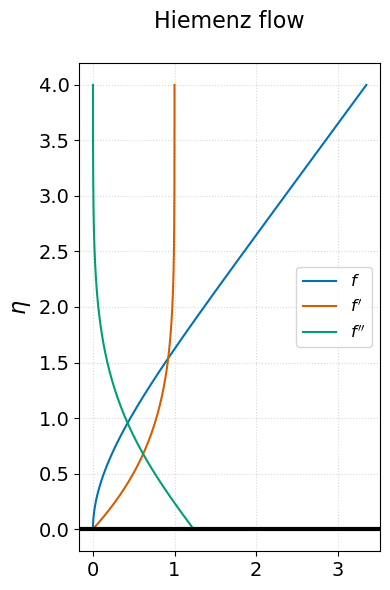

In [578]:
# grab arrays for f, fp = f' and fpp = f''
eta_plot = np.linspace(0, 4, 201)
f_plot = res.sol(eta_plot)[0]
fp_plot = res.sol(eta_plot)[1]
fpp_plot = res.sol(eta_plot)[2]

fig, ax = plt.subplots(tight_layout=True)

ax.plot(f_plot, eta_plot, color='#0072B2', label="$f$")
ax.plot(fp_plot, eta_plot, color='#D55E00', label="$f'$")
ax.plot(fpp_plot, eta_plot, color='#009E73', label="$f''$")

# the wall
ax.axhline(0, color='black', linewidth=3)

ax.grid(alpha=0.5, linestyle='dotted')
ax.legend()

ax.set_ylabel(r"$\eta$")
ax.set_title("Hiemenz flow")

fig.set_size_inches(4, 6)

#fig.savefig("hiemenz.pdf") # bbox_inches='tight'

## Discussion

### Thickness of the viscous ("boundary") layer

In [579]:
def fp99eq(eta):
    return res.sol(eta)[1] - 0.99

# solve f' - 0.99 = 0 with initial guess eta = 2
sol = nsolve(fp99eq, x0=2, rtol=mytol)
eta99 = sol.root
print(" solution of f'(eta) = 0.99 is eta_99% =", eta99)

 solution of f'(eta) = 0.99 is eta_99% = 2.3794184371127867


So, $\delta_{99\%} = \eta_{99\%}\sqrt{\nu/a} \approx 2.38\sqrt{\nu/a}$, which Panton rounds to $2.40\sqrt{\nu/a}$ in Eq. (11.9.20). In terms of the local Reynolds number $Re_x = v_{x,e}x/\nu = ax^2/\nu$, this is $\delta_{99\%} = \eta_{99\%}\,x\,Re_x^{-1/2}$, the same form as for the Blasius BL. But here $Re_x \propto x^2$, so the layer has the same thickness at every $x$, while the Blasius BL grows like $\sqrt{x}$.

### Displacement of the outer flow

The _displacement thickness_ is
$$
    \delta_d = \int_0^\infty \left(1 - \frac{v_x}{v_{x,e}}\right) dy = \sqrt{\nu/a}\int_0^\infty \big[1 - f'(\eta)\big]\, d\eta = \sqrt{\nu/a}\;\eta_d,
$$
where
$$
    \eta_d = \lim_{\eta\to\infty}\big[\eta - f(\eta)\big]
$$
using $f(0)=0$. In other words, far from the wall ($\eta\to\infty$), $f'\to1$, and $f$ becomes a straight line of slope 1, $f \approx \eta - \eta_d$. This is why the limit defining $\eta_d$ exists.

In [580]:
# eta - f has stopped changing by eta = inf
eta_d = inf - res.sol(inf)[0]
print(" eta_d =", eta_d)

 eta_d = 0.6479004744020784


So, $\delta_d \approx 0.648\sqrt{\nu/a}$, and outside the viscous layer,
$$
    v_y \approx -a\big(y - \delta_d\big) = v_y^{\mathrm{ideal}}(x,y) + a\delta_d
$$
as in Panton, Eq. (11.9.19). The effect of viscosity is to shift the outer/external (ideal) flow away from the wall by the constant distance $\delta_d$.

### Wall shear stress

Since $v_y$ does not depend on $x$, the shear stress at the wall is
$$
    \tau_w(x) = \mu\left.\frac{\partial v_x}{\partial y}\right|_{y=0} = \mu v_{x,e}\sqrt{a/\nu}\, f''(0) = \rho v_{x,e}\sqrt{\nu a}\, f''(0).
$$
As for the Blasius BL, the friction coefficient is $C_f(x) = \tau_w(x)/(\tfrac{1}{2}\rho v_{x,e}^2) = 2f''(0)\,Re_x^{-1/2}$. But here $Re_x \propto x^2$, so $\tau_w$ grows linearly with $x$, while for the Blasius BL it decays like $x^{-1/2}$.

In [581]:
fpp0 = res.sol(0)[2]
print(f"f''(0) = {fpp0:.10f}")

f''(0) = 1.2325876568


# VISUALIZATION

## Comparison to ideal flow

In dimensionless form, with $x^* = x/\sqrt{\nu/a}$ and $\eta = y/\sqrt{\nu/a}$ playing the role of $y^*$, the dimensionless streamfunctions ($\psi$ scaled by $\nu$) are
$$
    \psi_{\mathrm{ideal}}^*(x^*,\eta) = x^*\eta, \qquad \psi_{\mathrm{Hiemenz}}^*(x^*,\eta) = x^* f(\eta).
$$
Let us plot the same streamlines for both.

In [582]:
# grid in dimensionless coordinates
xs, ys = np.meshgrid(np.linspace(-4, 4, num=201),
                     np.linspace(0, 4, num=201))

# res.sol takes a 1D array, so flatten the grid and reshape back
f_flat = res.sol(ys.flatten())[0]
f_grid = f_flat.reshape(ys.shape)

psi_ideal = xs*ys
psi_visc = xs*f_grid

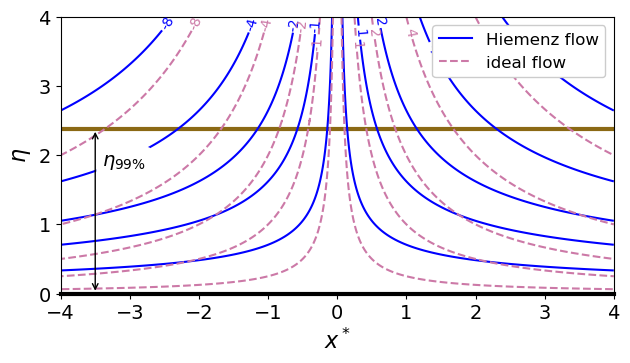

In [583]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel(r'$\eta$')
ax.set_aspect('equal')

levels = [-8, -4, -2, -1, -0.25, 0.25, 1, 2, 4, 8]

# skip the labels for +/-0.25, which crowd the stagnation streamline
label_levels = [-8, -4, -2, -1, 1, 2, 4, 8]

# plot viscous streamlines; linestyles='solid' is needed because
# Matplotlib draws negative contour levels dashed by default
cspsi = ax.contour(xs, ys, psi_visc, levels, colors='blue', linestyles='solid')
# label the contours with their values
ax.clabel(cspsi, label_levels, inline=True, fmt='%g')

# plot ideal streamlines
cspsi_i = ax.contour(xs, ys, psi_ideal, levels, colors='#CC79A7', linestyles='dashed')
# label the contours with their values
ax.clabel(cspsi_i, label_levels, inline=True, fmt='%g')

# the wall and the edge of the viscous layer
ax.plot([-4, 4], [0, 0], color='black', linewidth=3, clip_on=False)
ax.plot([-4, 4], [eta99, eta99], color='#8B6914', linewidth=3, zorder=0)

# label the edge of the viscous layer with a double arrow
ax.text(-3.4, 1.85, r'$\eta_{99\%}$', fontdict={'size': 14},
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='none'))
ax.annotate("", (-3.5, 0), (-3.5, eta99), arrowprops={'arrowstyle': '<->'})

# add legend
legend_elements = [
    Line2D([0], [0], color='blue', label='Hiemenz flow'),
    Line2D([0], [0], color='#CC79A7', linestyle='dashed', label='ideal flow'),
]
ax.legend(handles=legend_elements, framealpha=1, loc='upper right');

Each viscous streamline lies farther from the wall than the ideal one: no slip slows the fluid near the wall, so the same flow rate needs more room. Above the viscous layer, the shift is the constant $\eta_d \approx 0.648$.

To see the displacement thickness, shift the ideal flow away from the wall by $\eta_d$:
$$
    \psi_{\mathrm{shifted}}^* = x^*(\eta - \eta_d),
$$
which is now an ideal flow toward a wall at $\eta = \eta_d$. Above the viscous layer, its streamlines should match the Hiemenz ones.

In [584]:
psi_shifted = xs*(ys - eta_d)

# the shifted ideal flow only exists above the displaced wall
psi_shifted[ys < eta_d] = np.nan

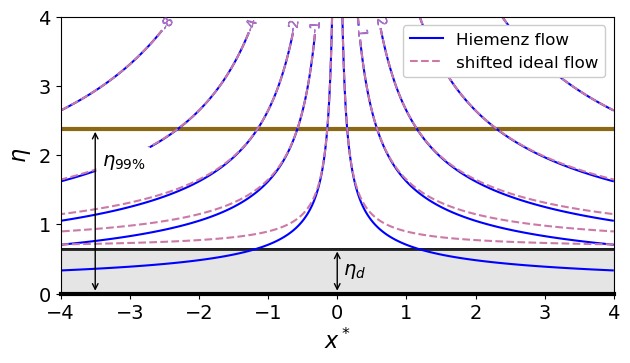

In [585]:
fig, ax = plt.subplots(tight_layout=True)
ax.set_xlabel('$x^*$')
ax.set_ylabel(r'$\eta$')
ax.set_aspect('equal')

# plot viscous streamlines
cspsi = ax.contour(xs, ys, psi_visc, levels, colors='blue', linestyles='solid')
# label the contours with their values
ax.clabel(cspsi, label_levels, inline=True, fmt='%g')

# plot shifted ideal streamlines
cspsi_s = ax.contour(xs, ys, psi_shifted, levels, colors='#CC79A7', linestyles='dashed')
# label the contours with their values
ax.clabel(cspsi_s, label_levels, inline=True, fmt='%g')

# the wall, the displaced wall and the edge of the viscous layer
ax.plot([-4, 4], [0, 0], color='black', linewidth=3, clip_on=False)
ax.plot([-4, 4], [eta_d, eta_d], color='black', linewidth=2, zorder=0)
# shade the displacement thickness, between the two walls
ax.axhspan(0, eta_d, color='gray', alpha=0.2, zorder=0)
ax.plot([-4, 4], [eta99, eta99], color='#8B6914', linewidth=3, zorder=0)

# label the edge of the viscous layer with a double arrow
ax.text(-3.4, 1.85, r'$\eta_{99\%}$', fontdict={'size': 14},
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='none'))
ax.annotate("", (-3.5, 0), (-3.5, eta99), arrowprops={'arrowstyle': '<->'})

# label the displacement thickness, the gap between the two walls
ax.text(0.08, 0.275, r'$\eta_d$', fontdict={'size': 14})
ax.annotate("", (0, 0), (0, eta_d), arrowprops={'arrowstyle': '<->'})

# add legend
legend_elements = [
    Line2D([0], [0], color='blue', label='Hiemenz flow'),
    Line2D([0], [0], color='#CC79A7', linestyle='dashed', label=r'shifted ideal flow'),
]
ax.legend(handles=legend_elements, framealpha=1, loc='upper right');

Above $\eta_{99\%}$, the two sets of streamlines coincide: from outside the viscous layer, the flow looks like ideal flow toward a wall at $y = \delta_d$.

## Dimensional flow field

For water, let us plot the velocity near the wall in millimeters and vary the strain rate $a$.

In [586]:
# kinematic viscosity of water
nu_water = 1e-6  # m^2/s

In [587]:
def plot_Hiemenz_dimensional(a):
    # grid, in mm
    x, y = np.meshgrid(np.linspace(-5, 5, num=11),
                       np.linspace(0.25, 4.75, num=10))

    # viscous length scale sqrt(nu/a), in mm
    ell = np.sqrt(nu_water/a)*1e3

    # evaluate the solution at the grid points
    eta_q = (y/ell).flatten()
    f_q = res.sol(eta_q)[0].reshape(y.shape)
    fp_q = res.sol(eta_q)[1].reshape(y.shape)

    # velocity in mm/s, using sqrt(a*nu) = a*ell
    vx = a*x*fp_q
    vy = -a*ell*f_q

    fig, ax = plt.subplots(tight_layout=True)
    ax.set_xlabel('$x$ [mm]')
    ax.set_ylabel('$y$ [mm]')
    ax.set_ylim(0, 5.5)

    # scale the arrows with a, so that their length stays the same
    qs = 5*a
    qv = ax.quiver(x, y, vx, vy, scale=qs, scale_units='xy', color='blue')
    ax.quiverkey(qv, 0.7, 0.93, 5*a, f'{5*a:.2f} mm/s', labelpos='E',
                 coordinates='axes', fontproperties={'size': 14})

    # the wall and the edge of the viscous layer
    ax.plot([-6, 6], [0, 0], color='black', linewidth=3, clip_on=False)
    ax.plot([-6, 6], [eta99*ell, eta99*ell], color='#8B6914',
            linewidth=3, zorder=0, label=r'$\delta_{99\%}$')
    ax.set_xlim(-6, 6)

    ax.grid(alpha=0.5, linestyle='dotted')
    ax.legend(loc='upper left')

    plt.show()

First, a static plot.

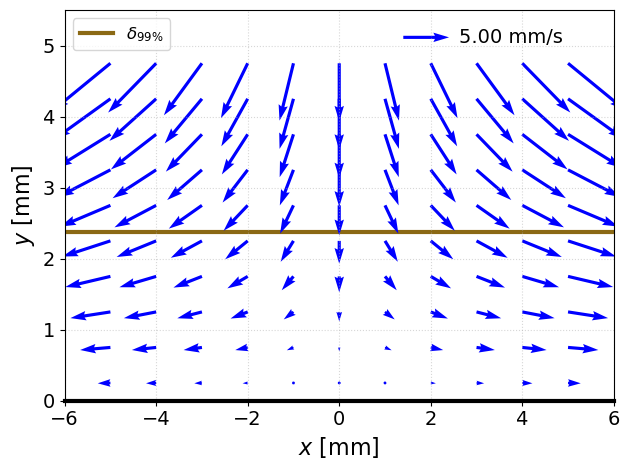

In [588]:
plot_Hiemenz_dimensional(1)

Then, an [`interact`](https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html) widget will let us vary $a$ (in s<sup>&minus;1</sup>).

In [589]:
# keep a <= 2, so that eta stays below inf on this grid
interact(plot_Hiemenz_dimensional,
         a=widgets.FloatSlider(value=1, min=0.25, max=2, step=0.25, description='strain a'));

A larger strain rate, from a faster stream or a smaller body, makes the viscous layer thinner, because $\delta_{99\%}\propto\sqrt{\nu/a}$.

# FURTHER EXPLORATION

On your own:
*   Near the wall ($\eta \ll 1$), since $f(0) = f'(0) = 0$, the leading term of its Taylor series is
    $$
        f \approx \tfrac{1}{2}f''(0)\,\eta^2.
    $$
    Show that Hiemenz flow then reduces to the Stokes stagnation point flow,
    $$
        \psi_{\mathrm{Stokes}}(x,y) = C x y^2,\qquad C = \tfrac{1}{2}f''(0)\sqrt{a^3/\nu},
    $$
    and check with SymPy that it satisfies the biharmonic equation (see [Stokes flows in 2D](../Stokes_flows_2D.ipynb)). Add the Stokes streamlines to the comparison plot: where does each of the three flows (ideal, Hiemenz and Stokes) apply?

*   The pressure field is found _a posteriori_ from COLM. For the ideal flow, check with SymPy that Bernoulli's equation,
    $$
        p(x,y) = p_0 - \frac{1}{2}\rho v_{x,e}^2 = p_0 - \frac{1}{2}\rho a^2(x^2+y^2),
    $$
    gives $\underline{R} + \nabla p = \underline{0}$; along the wall, it is $-\tfrac{dp}{dx} = \rho v_{x,e}\tfrac{dv_{x,e}}{dx}$, as in the boundary layers notebook. For Hiemenz flow, integrate COLM to find Panton's Eq. (11.9.22),
    $$
        p(x,y) = p_0 - \frac{1}{2}\rho v_{x,e}^2 - \mu a\left[\frac{1}{2}f(\eta)^2 + f'(\eta)\right],
    $$
    and check it the same way. Why is $\partial p/\partial y \approx 0$ across the viscous layer, as the BL approximation assumes?

*   Near the front stagnation point of the ideal flow past a cylinder of radius $r_0$ in a uniform stream $V_0$ (see [ideal flows in 2D](../ideal_flows_2D.ipynb)), show that, near the stagnation point, $v_{x,e} \approx (2V_0/r_0)\,x$, so that $a = 2V_0/r_0$ (Panton, Eq. (11.9.21)). Then, estimate $\delta_{99\%}$ for $r_0 = 5$ cm and $V_0 = 15$ cm/s in air ($\nu = 0.15$ cm<sup>2</sup>/s).

*   For flow toward a stagnation point on an axisymmetric body, with the wall at $z=0$, [Homann (1936)](https://doi.org/10.1002/zamm.19360160304) ([English translation](https://ntrs.nasa.gov/citations/19930093896)) proposed that
    $$
        v_r(r,z) = arf'(\eta), \qquad v_z(r,z) = -2\sqrt{a\nu}\,f(\eta), \qquad \eta = \frac{z}{\sqrt{\nu/a}}.
    $$
    Use SymPy in cylindrical coordinates, as in the derivation above, to find the ODE for $f$, and compare it with Panton, Sect. 20.12. Then, solve the BVP and compare $\eta_{99\%}$ with that of Hiemenz flow.

*   The Hiemenz BCs also admit a second, "dual," solution, found by [Libby (1967)](https://doi.org/10.2514/3.4008) and [Davey & Schofield (1967)](https://doi.org/10.1017/S0022112067001958) and described in Panton's Problem 20.28. Which assumption in our form of $\underline{v}$ rules it out?

# REFERENCES

A. Davey, D. Schofield, Three-dimensional flow near a two-dimensional stagnation point, _J. Fluid Mech._ **28** (1967) 149&ndash;151. [doi:10.1017/S0022112067001958](https://doi.org/10.1017/S0022112067001958)

K. Hiemenz, Die Grenzschicht an einem in den gleichf&ouml;rmigen Fl&uuml;ssigkeitsstrom eingetauchten geraden Kreiszylinder, _Dinglers Polytech. J._ **326** (1911) 321&ndash;324 and continuations. [Full text](https://archive.org/details/dinglers-polytechnisches-journal-vol-326/page/321/mode/2up)

F. Homann, Der Einflu&szlig; gro&szlig;er Z&auml;higkeit bei der Str&ouml;mung um den Zylinder und um die Kugel, _Z. Angew. Math. Mech._ **16** (1936) 153&ndash;164. [doi:10.1002/zamm.19360160304](https://doi.org/10.1002/zamm.19360160304). English translation: The effect of high viscosity on the flow around a cylinder and around a sphere, NACA Technical Memorandum 1334, 1952. [Full text](https://ntrs.nasa.gov/citations/19930093896)

P. A. Libby, Heat and mass transfer at a general three-dimensional stagnation point, _AIAA J._ **5** (1967) 507&ndash;517. [doi:10.2514/3.4008](https://doi.org/10.2514/3.4008)

R. L. Panton, _Incompressible Flow_, 4th ed., Wiley, 2013. [doi:10.1002/9781118713075](https://doi.org/10.1002/9781118713075)